# CTR / Engagement Opportunity Scoring: notebook 1

**Question:** which visible pages get fewer clicks than we would expect for where they rank, and which should be reviewed first?

**Approach (plain words):** learn what CTR is *normal* for a page given its position, visibility and content type, using pages from other clients. Then score each page by how far its real CTR falls below that expectation, and rank by the clicks it appears to be missing.

Data: `FlyRank/internship-lanes`, lane `engagement_fix` (a fixed example cut, not the full warehouse). Everything below is *observed* / *directional*, not causal.

In [1]:
# 1. Setup and load. Needs a Colab secret named HF_TOKEN (Secrets key icon, Notebook access ON).
!pip install -q datasets huggingface_hub
from google.colab import userdata
from huggingface_hub import login
login(userdata.get("HF_TOKEN"))

import numpy as np
import pandas as pd
from datasets import load_dataset

ds = load_dataset("FlyRank/internship-lanes", "engagement_fix")
df = ds["train"].to_pandas()
print(df.shape)

README.md:   0%|          | 0.00/2.98k [00:00<?, ?B/s]

default_lanes/engagement_fix.parquet: reconstructing file:   0%|          |  0.00B /  760kB            

default_lanes/engagement_fix.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/33202 [00:00<?, ? examples/s]

(33202, 31)


In [2]:
# 2. First look: missing values and what the number columns look like
print(df.isna().sum()[df.isna().sum() > 0].to_string())
print()
cols = ["impressions_30d", "clicks_30d", "ctr_30d", "avg_position_30d", "health_score"]
print(df[cols].describe().round(2).to_string())
print("\nClients:", df["client_hash_id"].nunique(), "| Pages:", df["content_hash_id"].nunique())

word_count_tier     5680
char_count_tier     5680
ctr_30d              358
avg_position_30d     358

       impressions_30d  clicks_30d   ctr_30d  avg_position_30d  health_score
count         33202.00    33202.00  32844.00          32844.00      33202.00
mean           4408.47       22.85      0.45             13.07         47.68
std           11086.94      725.73      0.70             11.44         13.01
min               0.00        0.00      0.00              0.00         10.00
25%             417.00        1.00      0.08              5.80         40.00
50%            1607.00        7.00      0.31              9.20         50.00
75%            4285.00       17.00      0.63             18.40         60.00
max          576250.00    97954.00     53.22            122.60         85.00

Clients: 44 | Pages: 33202


In [3]:
# 3. Is ctr_30d a fraction or a percent? Compare with clicks / impressions.
has_imp = df["impressions_30d"] > 0
calc = (df.loc[has_imp, "clicks_30d"] / df.loc[has_imp, "impressions_30d"])
print("Median ctr_30d in the data:", df.loc[has_imp, "ctr_30d"].median())
print("Median clicks/impressions :", round(calc.median(), 4))
print("Correlation               :", round(np.corrcoef(calc, df.loc[has_imp, "ctr_30d"])[0, 1], 4))
print("Pages with zero impressions:", (~has_imp).sum())

Median ctr_30d in the data: 0.31
Median clicks/impressions : 0.0031
Correlation               : 1.0
Pages with zero impressions: 358


## Label audit: is `needs_ctr_fix` a real outcome or a rule?

The dataset already has flags like `needs_ctr_fix`. If a flag is just a rule on CTR and position, a model trained to predict it only re-discovers that rule, which looks accurate but teaches nothing. Test it: fit a very shallow tree on CTR, position and impressions and see how well it recovers the flag.

In [4]:
# 4. Can a tiny tree recover needs_ctr_fix from CTR, position and impressions alone?
from sklearn.tree import DecisionTreeClassifier, export_text

feats = ["ctr_30d", "avg_position_30d", "impressions_30d"]
sub = df.dropna(subset=feats + ["needs_ctr_fix"])
tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(sub[feats], sub["needs_ctr_fix"].astype(int))
acc = tree.score(sub[feats], sub["needs_ctr_fix"].astype(int))
print(f"needs_ctr_fix share of pages: {sub['needs_ctr_fix'].mean():.3f}")
print(f"Depth-3 tree accuracy at recovering it: {acc:.3f}")
print(export_text(tree, feature_names=feats))
print("Overall flag shares:")
print(df[["needs_ctr_fix", "needs_engagement_fix", "is_quick_win", "ai_opportunity"]].mean().round(3).to_string())

needs_ctr_fix share of pages: 0.411
Depth-3 tree accuracy at recovering it: 0.998
|--- avg_position_30d <= 10.05
|   |--- impressions_30d <= 98.50
|   |   |--- class: 0
|   |--- impressions_30d >  98.50
|   |   |--- ctr_30d <= 2.00
|   |   |   |--- class: 1
|   |   |--- ctr_30d >  2.00
|   |   |   |--- class: 0
|--- avg_position_30d >  10.05
|   |--- class: 0

Overall flag shares:
needs_ctr_fix           0.407
needs_engagement_fix    1.000
is_quick_win            0.190
ai_opportunity          0.470


**How to read this:** if that tree gets close to 100%, the flag is a rule on those columns, so it is *not* a good thing to predict. That is why this notebook builds its own expectation of CTR instead of predicting the flag. The flag is used later only as a rough sanity check.

In [5]:
# 5. Analysis set: pages with enough impressions for CTR to mean something
MIN_IMP = 100
d = df[(df["impressions_30d"] >= MIN_IMP) & df["avg_position_30d"].notna()].copy()
d["ctr"] = d["clicks_30d"] / d["impressions_30d"]
print(f"Kept {len(d):,} of {len(df):,} pages ({len(d)/len(df):.1%}) with >= {MIN_IMP} impressions")
print("Clients kept:", d["client_hash_id"].nunique())
print("Median CTR:", round(d["ctr"].median(), 4), "| Mean CTR:", round(d["ctr"].mean(), 4))

Kept 28,078 of 33,202 pages (84.6%) with >= 100 impressions
Clients kept: 38
Median CTR: 0.0038 | Mean CTR: 0.0052


## Honest validation design

* **Grouped split by client.** Pages from one client look alike. If the same client sits in train and test, the model can memorise the client and look better than it is. So whole clients are held out.
* **Features used:** position, impressions, content type, intent, age, freshness, length tiers. **Not used:** clicks, sessions, pageviews, engagement and the pre-made flags, because they come from the same clicks we are judging or are derived from CTR.
* **Baseline:** the median CTR for each position bucket, learned on training clients only.

In [6]:
# 6. Grouped split, baseline and model on the same held-out clients
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

CAT = ["content_type", "main_intent", "age_tier", "freshness_tier", "word_count_tier", "char_count_tier"]
NUM = ["avg_position_30d", "log_impressions"]
d["log_impressions"] = np.log1p(d["impressions_30d"])
for c in CAT:
    d[c] = d[c].astype(str)

X, y, g = d[CAT + NUM], d["ctr"], d["client_hash_id"]
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr, te = next(gss.split(X, y, groups=g))
Xtr, Xte, ytr, yte = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
print(f"Train: {len(tr):,} pages / {g.iloc[tr].nunique()} clients | Test: {len(te):,} pages / {g.iloc[te].nunique()} clients")
assert set(g.iloc[tr]).isdisjoint(set(g.iloc[te])), "client leakage!"

# Baseline: median CTR per position bucket
bins = [0, 1.5, 2.5, 3.5, 4.5, 5.5, 7.5, 10.5, 15.5, 20.5, 1000]
def bucket(s): return pd.cut(s, bins=bins, labels=False)
base_table = ytr.groupby(bucket(Xtr["avg_position_30d"])).median()
base_pred = bucket(Xte["avg_position_30d"]).map(base_table).fillna(ytr.median())

pre = ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT)],
                        remainder="passthrough")
model = Pipeline([("pre", pre), ("gbm", HistGradientBoostingRegressor(max_iter=200, learning_rate=0.06, random_state=42))])
model.fit(Xtr, ytr)
pred = np.clip(model.predict(Xte), 0, 1)

mae_b, mae_m = mean_absolute_error(yte, base_pred), mean_absolute_error(yte, pred)
r2_b, r2_m = r2_score(yte, base_pred), r2_score(yte, pred)
print(f"Baseline (median CTR by position): MAE {mae_b:.4f} | R2 {r2_b:.3f}")
print(f"Model (position + content features): MAE {mae_m:.4f} | R2 {r2_m:.3f}")
print(f"MAE change vs baseline: {(mae_m - mae_b) / mae_b:+.1%}")

Train: 24,786 pages / 30 clients | Test: 3,292 pages / 8 clients
Baseline (median CTR by position): MAE 0.0034 | R2 -0.000
Model (position + content features): MAE 0.0031 | R2 0.051
MAE change vs baseline: -10.7%


In [7]:
# 7. Score every page with a model that never saw its client (out-of-fold, grouped)
from sklearn.model_selection import GroupKFold, cross_val_predict

n_groups = g.nunique()
k = min(5, n_groups)
oof = np.clip(cross_val_predict(model, X, y, groups=g, cv=GroupKFold(n_splits=k)), 0, 1)
d["expected_ctr"] = oof
d["ctr_gap"] = d["expected_ctr"] - d["ctr"]
d["missed_clicks"] = (d["ctr_gap"].clip(lower=0) * d["impressions_30d"]).round(1)

def reasons(r):
    out = []
    if r["ctr_gap"] > 0 and r["ctr"] < 0.5 * r["expected_ctr"]: out.append("CTR under half of expected")
    elif r["ctr_gap"] > 0: out.append("CTR below expected")
    if 3.5 < r["avg_position_30d"] <= 10.5: out.append("striking distance (position 4-10)")
    if r["impressions_30d"] >= d["impressions_30d"].quantile(0.75): out.append("high visibility")
    return "; ".join(out) if out else "no action flagged"
d["reason_codes"] = d.apply(reasons, axis=1)

top = d.sort_values("missed_clicks", ascending=False)
show = ["content_hash_id", "content_type", "avg_position_30d", "impressions_30d", "ctr", "expected_ctr", "missed_clicks", "reason_codes"]
print("Top 15 pages by estimated missed clicks (local use only, do NOT publish IDs):")
print(top[show].head(15).round(4).to_string(index=False))

Top 15 pages by estimated missed clicks (local use only, do NOT publish IDs):
         content_hash_id    content_type  avg_position_30d  impressions_30d    ctr  expected_ctr  missed_clicks                                                                   reason_codes
content_de7b73c0c9236725 keyword article               2.3           576250 0.0074        0.0544        27130.4                                    CTR under half of expected; high visibility
content_17ae923ddf4c4df9 keyword article               2.1           497301 0.0055        0.0544        24361.7                                    CTR under half of expected; high visibility
content_858a8680e22bd5bd keyword article               2.2           226978 0.0032        0.0544        11623.8                                    CTR under half of expected; high visibility
content_30c57ff3ce2a3644 keyword article               2.4           127805 0.0022        0.0544         6680.9                                    CTR under h

needs_ctr_fix rate among our top 1000: 0.912 vs 0.481 across all kept pages
Share of all missed clicks in our top 1000: 64.0%


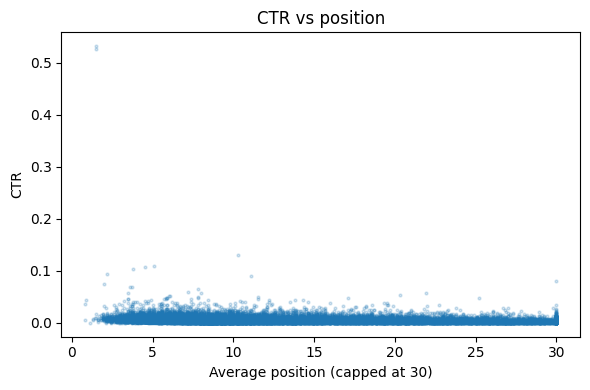

In [8]:
# 8. Rough sanity check against the pre-made flag (directional only)
N = min(1000, len(top) // 10)
top_flag = top.head(N)["needs_ctr_fix"].mean()
base_flag = d["needs_ctr_fix"].mean()
print(f"needs_ctr_fix rate among our top {N}: {top_flag:.3f} vs {base_flag:.3f} across all kept pages")
print(f"Share of all missed clicks in our top {N}: {top.head(N)['missed_clicks'].sum() / top['missed_clicks'].sum():.1%}")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(d["avg_position_30d"].clip(upper=30), d["ctr"], s=4, alpha=0.2, label="pages")
order = d["avg_position_30d"].clip(upper=30).argsort()
ax.set_xlabel("Average position (capped at 30)"); ax.set_ylabel("CTR"); ax.set_title("CTR vs position")
plt.tight_layout(); plt.show()

In [9]:
# 9. Numbers to copy back to me (no IDs, no client info)
print("===== COPY EVERYTHING BELOW THIS LINE AND SEND IT TO ME =====")
print(f"Rows total: {len(df)} | kept (>= {MIN_IMP} impressions): {len(d)} | clients kept: {d['client_hash_id'].nunique()}")
print(f"needs_ctr_fix share: {sub['needs_ctr_fix'].mean():.3f} | depth-3 tree recovers it with accuracy {acc:.3f}")
print(f"Test: {len(te)} pages / {g.iloc[te].nunique()} clients")
print(f"Baseline MAE {mae_b:.4f} R2 {r2_b:.3f} | Model MAE {mae_m:.4f} R2 {r2_m:.3f}")
print(f"needs_ctr_fix rate among top {N}: {top_flag:.3f} vs {base_flag:.3f} overall")
print(f"Share of missed clicks in top {N}: {top.head(N)['missed_clicks'].sum() / top['missed_clicks'].sum():.1%}")
print("Reason code counts in top", N)
print(top.head(N)["reason_codes"].value_counts().head(6).to_string())

===== COPY EVERYTHING BELOW THIS LINE AND SEND IT TO ME =====
Rows total: 33202 | kept (>= 100 impressions): 28078 | clients kept: 38
needs_ctr_fix share: 0.411 | depth-3 tree recovers it with accuracy 0.998
Test: 3292 pages / 8 clients
Baseline MAE 0.0034 R2 -0.000 | Model MAE 0.0031 R2 0.051
needs_ctr_fix rate among top 1000: 0.912 vs 0.481 overall
Share of missed clicks in top 1000: 64.0%
Reason code counts in top 1000
reason_codes
CTR under half of expected; striking distance (position 4-10); high visibility    647
CTR under half of expected; high visibility                                       153
CTR below expected; striking distance (position 4-10); high visibility            135
CTR below expected; high visibility                                                35
CTR under half of expected                                                         29
CTR below expected                                                                  1


In [1]:
!pip install -q duckdb huggingface_hub
import duckdb
from google.colab import userdata

con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute(f"CREATE SECRET hf_secret (TYPE HUGGINGFACE, TOKEN '{userdata.get('HF_TOKEN')}')")
base = "hf://datasets/FlyRank/internship-warehouse"

tables = ["dim_clients.parquet", "dim_content.parquet",
          "fact_content_daily_performance_sample.parquet", "fact_content_query_90d.parquet"]
for t in tables:
    print("====", t)
    cols = con.sql(f"DESCRIBE SELECT * FROM '{base}/{t}'").df()[["column_name", "column_type"]]
    print(cols.to_string(index=False))
    print("rows:", con.sql(f"SELECT count(*) FROM '{base}/{t}'").fetchone()[0])

print("\n==== 2 sample rows of the daily fact table ====")
print(con.sql(f"SELECT * FROM '{base}/fact_content_daily_performance_sample.parquet' LIMIT 2").df().T.to_string())

==== dim_clients.parquet
        column_name column_type
     client_hash_id     VARCHAR
          is_active     BOOLEAN
     has_gsc_access     BOOLEAN
     has_ga4_access     BOOLEAN
     access_profile     VARCHAR
client_created_date        DATE
client_updated_date        DATE
     gsc_data_start        DATE
     ga4_data_start        DATE
rows: 104
==== dim_content.parquet
               column_name column_type
            client_hash_id     VARCHAR
           content_hash_id     VARCHAR
           keyword_hash_id     VARCHAR
               url_hash_id     VARCHAR
        keyword_char_count      BIGINT
       keyword_token_count      BIGINT
            url_char_count      BIGINT
      content_created_date        DATE
      content_updated_date        DATE
              content_type     VARCHAR
             search_volume      BIGINT
               competition      DOUBLE
         competition_level     VARCHAR
                       cpc      DOUBLE
               main_intent     VARC